In [24]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [37]:
path = r"C:\Users\PRASANNA\OneDrive\Attachments\Desktop\DL datasets\Pneumonia X Ray\chest_xray"

In [38]:
train_dir = path + "/train"
test_dir = path + "/test"
val_dir = path + "/val"

In [39]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

In [40]:
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=32,
    color_mode='grayscale',
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=32,
    color_mode='grayscale',
    class_mode='binary',
    shuffle=False
)

val_data = val_datagen.flow_from_directory(
    val_dir,
    target_size=(150, 150),
    batch_size=32,
    color_mode='grayscale',
    class_mode='binary'
)

Found 4295 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


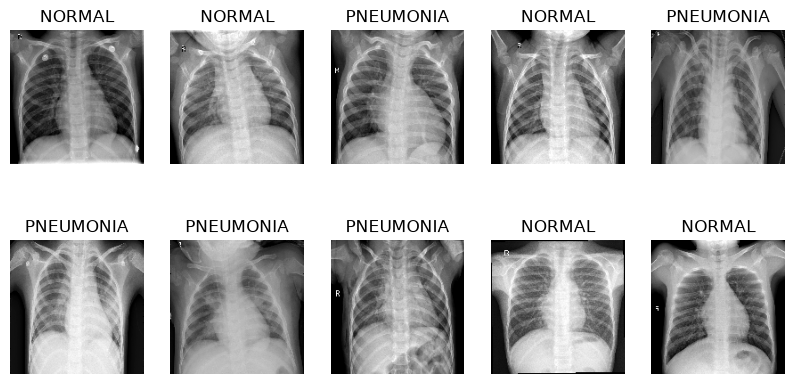

In [42]:
class_names = list(train_data.class_indices.keys())
images, labels = next(train_data)
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(class_names[int(labels[i])])
    plt.axis('off')

plt.show()

In [44]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='relu')
])

In [45]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [46]:
h = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 59s 425ms/step - accuracy: 0.6854 - loss: 5.0081 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 2/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 61s 447ms/step - accuracy: 0.6878 - loss: 4.9776 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 3/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 57s 421ms/step - accuracy: 0.6878 - loss: 4.9776 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 4/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 58s 430ms/step - accuracy: 0.6878 - loss: 4.9776 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 5/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 58s 431ms/step - accuracy: 0.6878 - loss: 4.9776 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 6/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 61s 452ms/step - accuracy: 0.6878 - loss: 4.9776 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 7/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 57s 424ms/step - accuracy: 0.6878 - loss: 4.9776 - val_accuracy: 0.5000 - val_loss: 7.9712
Epoch 8/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 55s 405ms/step - accuracy: 0.6878 - loss: 4

In [87]:
test_loss, test_acc = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc * 100, "%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step - accuracy: 0.6250 - loss: 5.9784 
Test Loss: 5.978394031524658
Test Accuracy: 62.5 %


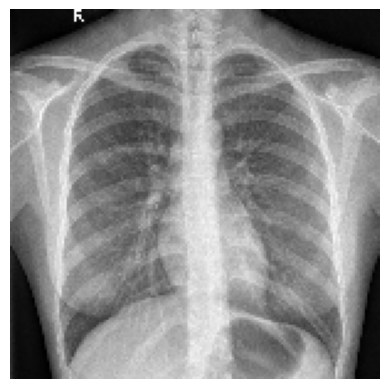

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Actual Class: NORMAL
Predicted Class: PNEUMONIA


In [94]:
images, labels = test_data[0]

n = random.randint(0, len(images)-1)

plt.imshow(images[n].squeeze(), cmap='gray')
plt.axis('off')
plt.show()

pred = model.predict(images[n:n+1])

predicted_class = int(pred[0][0] >= 0.5)
actual_class = int(labels[n])

print("Actual Class:", class_names[actual_class])
print("Predicted Class:", class_names[predicted_class])

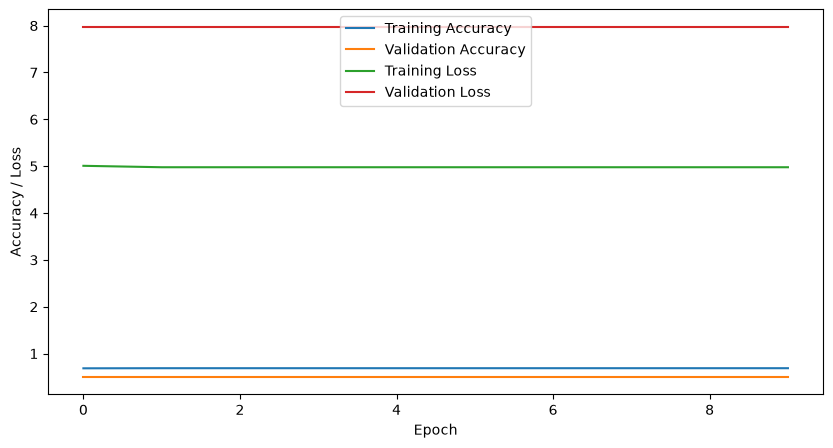

In [67]:
plt.figure(figsize=(10, 5))

plt.plot(h.history['accuracy'], label='Training Accuracy')
plt.plot(h.history['val_accuracy'], label='Validation Accuracy')

plt.plot(h.history['loss'], label='Training Loss')
plt.plot(h.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Accuracy / Loss')

plt.legend()

plt.show()